In [ ]:
import os

print("Files available in Google Colab:\n")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [
        d for d in dirs
        if d not in ["sample_data", ".config"]
    ]

    for filename in files:
        if filename.lower().endswith(
            (".csv", ".xlsx", ".xls", ".parquet", ".zip")
        ):
            print(os.path.join(root, filename))

Files available in Google Colab:

/content/systems_20250729.csv


In [ ]:
import pandas as pd
import os

pvdaq_path = "/content/systems_20250729.csv"

# Inspect the source without modifying it
print("=" * 65)
print("PVDAQ SOURCE FILE INSPECTION")
print("=" * 65)

print("File exists:", os.path.exists(pvdaq_path))
print("File size (MB):", round(os.path.getsize(pvdaq_path) / (1024**2), 2))

# Read the CSV
df_pvdaq = pd.read_csv(pvdaq_path, low_memory=False)

print("\nDataset shape:", df_pvdaq.shape)

print("\nColumn names:")
for i, col in enumerate(df_pvdaq.columns, 1):
    print(f"{i}. {col}")

print("\nData types:")
print(df_pvdaq.dtypes)

print("\nFirst 5 rows:")
display(df_pvdaq.head())

print("\nLast 5 rows:")
display(df_pvdaq.tail())

print("\nMemory usage (MB):",
      round(df_pvdaq.memory_usage(deep=True).sum() / (1024**2), 2))

PVDAQ SOURCE FILE INSPECTION
File exists: True
File size (MB): 0.37

Dataset shape: (1862, 31)

Column names:
1. system_id
2. system_public_name
3. site_location
4. timezone_or_utc_offset
5. latitude
6. longitude
7. elevation_m
8. dc_capacity_kW
9. kg_climate
10. pvcz_composite
11. pvcz_t_rack
12. pvcz_t_roof
13. pvcz_humidity
14. pvcz_wind
15. tracking
16. type
17. azimuth
18. tilt
19. first_timestamp
20. last_timestamp
21. years
22. number_records
23. dataset_size_mb
24. available_sensor_channels
25. qa_status
26. qa_issue
27. Unnamed: 26
28. Unnamed: 27
29. Unnamed: 28
30. Unnamed: 29
31. Unnamed: 30

Data types:
system_id                      int64
system_public_name            object
site_location                 object
timezone_or_utc_offset        object
latitude                     float64
longitude                    float64
elevation_m                  float64
dc_capacity_kW               float64
kg_climate                    object
pvcz_composite                 int64
pvcz_t

,system_id,system_public_name,site_location,timezone_or_utc_offset,latitude,longitude,elevation_m,dc_capacity_kW,kg_climate,pvcz_composite,...,number_records,dataset_size_mb,available_sensor_channels,qa_status,qa_issue,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30
0,2,Residential 1a,"Lakewood, CO",America/Denver,39.7214,-105.0972,1675.0,2.912,Dfb,12,...,13685898.0,313.25,7,fail,less than 1.0 years data,NaN,NaN,NaN,NaN,NaN
1,3,Residential 1b,"Lakewood, CO",America/Denver,39.7214,-105.0972,1675.0,2.720,Dfb,12,...,12668178.0,289.95,7,fail,NaN,NaN,NaN,NaN,NaN,NaN
2,4,NREL x-Si -1,"Golden, CO",7,39.7406,-105.1774,1795.3,1.000,BSk,12,...,113978017.0,2608.75,15,pass,"Filtered time series less than 1.0 years data,...",NaN,NaN,NaN,NaN,NaN
3,10,NREL CIS -1,"Golden, CO",7,39.7404,-105.1774,1792.8,1.120,BSk,12,...,113103574.0,2588.74,14,pass,Filtered time series less than 1.0 years data,NaN,NaN,NaN,NaN,NaN
4,33,Silicor Materials,"Golden, CO",7,39.7404,-105.1772,1794.0,2.400,BSk,12,...,113673602.0,2601.78,15,pass,"Percent clipping exceeded threshold of 10%, Fi...",NaN,NaN,NaN,NaN,NaN



Last 5 rows:


,system_id,system_public_name,site_location,timezone_or_utc_offset,latitude,longitude,elevation_m,dc_capacity_kW,kg_climate,pvcz_composite,...,number_records,dataset_size_mb,available_sensor_channels,qa_status,qa_issue,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30
1857,14760,PVDB_TADHC1036224,NaN,America/Los_Angeles,33.71677,-117.90680,16.204149,NaN,NaN,33,...,5179501.0,118.55,40,fail,NaN,NaN,NaN,NaN,NaN,NaN
1858,14761,PVDB_TADHC1036570,NaN,America/Los_Angeles,33.77269,-117.80076,83.785385,NaN,NaN,34,...,10565144.0,241.82,20,fail,NaN,NaN,NaN,NaN,NaN,NaN
1859,14762,PVDB_TADKC1017785,NaN,America/Los_Angeles,33.75678,-117.84557,49.351692,NaN,NaN,34,...,4303616.0,98.50,11,fail,NaN,NaN,NaN,NaN,NaN,NaN
1860,14763,PVDB_TADKC1018154,NaN,America/Los_Angeles,33.73392,-117.89290,20.376822,NaN,NaN,34,...,9738246.0,222.89,20,fail,NaN,NaN,NaN,NaN,NaN,NaN
1861,14764,PVDB_0022F20186EC,NaN,America/Los_Angeles,33.75245,-117.78435,94.976036,NaN,NaN,34,...,230328.0,5.27,10,fail,NaN,NaN,NaN,NaN,NaN,NaN



Memory usage (MB): 1.33


In [ ]:
# Preserve the original dataset
df_pvdaq_work = df_pvdaq.copy()

print("=" * 65)
print("PVDAQ — STAGE 1: MISSING-VALUE ASSESSMENT")
print("=" * 65)

# 1. Missing values by column
missing_report = pd.DataFrame({
    "Missing_Count": df_pvdaq_work.isna().sum(),
    "Missing_Percentage": (
        df_pvdaq_work.isna().mean() * 100
    ).round(2),
    "Data_Type": df_pvdaq_work.dtypes.astype(str)
})

print("\nMissing-value report:")
display(missing_report)

# 2. Completely empty columns
empty_columns = [
    col for col in df_pvdaq_work.columns
    if df_pvdaq_work[col].isna().all()
]

print("\nCompletely empty columns:")
print(empty_columns)

# 3. Rows containing missing values
print(
    "\nRows with at least one missing value:",
    df_pvdaq_work.isna().any(axis=1).sum()
)

# 4. Missing-value patterns
missing_patterns = (
    df_pvdaq_work.isna()
    .astype(int)
    .value_counts()
    .reset_index(name="Row_Count")
)

print("\nMost frequent missing-value patterns:")
display(missing_patterns.head(15))

# 5. Check empty strings separately
object_columns = df_pvdaq_work.select_dtypes(
    include="object"
).columns

empty_string_counts = (
    df_pvdaq_work[object_columns]
    .apply(lambda col: col.astype("string").str.strip().eq("").sum())
)

print("\nEmpty strings in text columns:")
display(empty_string_counts)

# 6. Confirm original data remains unchanged
print("\nOriginal shape:", df_pvdaq.shape)
print("Working-copy shape:", df_pvdaq_work.shape)

PVDAQ — STAGE 1: MISSING-VALUE ASSESSMENT

Missing-value report:


,Missing_Count,Missing_Percentage,Data_Type
system_id,0,0.00,int64
system_public_name,0,0.00,object
site_location,240,12.89,object
timezone_or_utc_offset,0,0.00,object
latitude,0,0.00,float64
longitude,0,0.00,float64
elevation_m,0,0.00,float64
dc_capacity_kW,65,3.49,float64
kg_climate,240,12.89,object
pvcz_composite,0,0.00,int64



Completely empty columns:
['Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30']

Rows with at least one missing value: 1862

Most frequent missing-value patterns:


,system_id,system_public_name,site_location,timezone_or_utc_offset,latitude,longitude,elevation_m,dc_capacity_kW,kg_climate,pvcz_composite,...,dataset_size_mb,available_sensor_channels,qa_status,qa_issue,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Row_Count
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,1,1,1,1285
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,1,1,1,285
2,0,0,1,0,0,0,0,0,1,0,...,0,0,0,0,1,1,1,1,1,169
3,0,0,1,0,0,0,0,0,1,0,...,0,0,0,1,1,1,1,1,1,45
4,0,0,0,0,0,0,0,1,0,0,...,0,0,0,1,1,1,1,1,1,37
5,0,0,1,0,0,0,0,1,1,0,...,0,0,0,1,1,1,1,1,1,26
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,1,1,1,8
7,0,0,0,0,0,0,0,0,0,0,...,1,0,0,1,1,1,1,1,1,2
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,1,1,1,2
9,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,1,1,1,1,2



Empty strings in text columns:


,0
system_public_name,0
site_location,0
timezone_or_utc_offset,0
kg_climate,0
tracking,0
type,0
first_timestamp,0
last_timestamp,0
qa_status,0
qa_issue,0



Original shape: (1862, 31)
Working-copy shape: (1862, 31)


In [ ]:
import pandas as pd
import numpy as np

print("=" * 70)
print("PVDAQ — STAGE 2: DATA INTEGRITY")
print("=" * 70)

df_pvdaq_integrity = df_pvdaq_work.copy()

# 1. Duplicate records
print("\n1. DUPLICATE ANALYSIS")

print("Exact duplicate rows:",
      df_pvdaq_integrity.duplicated().sum())

print("Rows participating in duplicate groups:",
      df_pvdaq_integrity.duplicated(keep=False).sum())

print("Unique system IDs:",
      df_pvdaq_integrity["system_id"].nunique())

print("Duplicate system IDs:",
      df_pvdaq_integrity["system_id"].duplicated().sum())

print("Duplicate public names:",
      df_pvdaq_integrity["system_public_name"].duplicated().sum())

# 2. Empty export columns
empty_columns = [
    col for col in df_pvdaq_integrity.columns
    if df_pvdaq_integrity[col].isna().all()
]

print("\n2. EMPTY EXPORT COLUMNS")
print(empty_columns)

# 3. Timestamp parsing
for col in ["first_timestamp", "last_timestamp"]:
    df_pvdaq_integrity[col + "_parsed"] = pd.to_datetime(
        df_pvdaq_integrity[col],
        errors="coerce",
        utc=True
    )

print("\n3. TIMESTAMP VALIDITY")

for col in ["first_timestamp", "last_timestamp"]:
    parsed_col = col + "_parsed"
    print(
        col,
        "| Invalid or missing:",
        df_pvdaq_integrity[parsed_col].isna().sum(),
        "| Earliest:",
        df_pvdaq_integrity[parsed_col].min(),
        "| Latest:",
        df_pvdaq_integrity[parsed_col].max()
    )

valid_dates = (
    df_pvdaq_integrity["first_timestamp_parsed"].notna()
    & df_pvdaq_integrity["last_timestamp_parsed"].notna()
)

date_reversed = (
    df_pvdaq_integrity.loc[valid_dates, "first_timestamp_parsed"]
    >
    df_pvdaq_integrity.loc[valid_dates, "last_timestamp_parsed"]
)

print("Systems with first timestamp after last timestamp:",
      date_reversed.sum())

# 4. Record-count and duration consistency
print("\n4. RECORD AND COVERAGE METADATA")

for col in [
    "years",
    "number_records",
    "dataset_size_mb",
    "available_sensor_channels"
]:
    print(f"\n{col}:")
    print(df_pvdaq_integrity[col].describe())

# 5. QA status
print("\n5. QA STATUS")

print(df_pvdaq_integrity["qa_status"].value_counts(dropna=False))

print("\nQA issue descriptions — most common:")
display(
    df_pvdaq_integrity["qa_issue"]
    .value_counts(dropna=False)
    .head(20)
    .rename_axis("QA_Issue")
    .reset_index(name="Count")
)

# 6. Metadata consistency checks
print("\n6. METADATA CONSISTENCY")

checks = {
    "Non-positive DC capacity": (
        df_pvdaq_integrity["dc_capacity_kW"].notna()
        & (df_pvdaq_integrity["dc_capacity_kW"] <= 0)
    ).sum(),

    "Negative number of records": (
        df_pvdaq_integrity["number_records"] < 0
    ).sum(),

    "Negative dataset size": (
        df_pvdaq_integrity["dataset_size_mb"] < 0
    ).sum(),

    "Negative sensor channel count": (
        df_pvdaq_integrity["available_sensor_channels"] < 0
    ).sum(),

    "Latitude outside [-90, 90]": (
        ~df_pvdaq_integrity["latitude"].between(-90, 90)
    ).sum(),

    "Longitude outside [-180, 180]": (
        ~df_pvdaq_integrity["longitude"].between(-180, 180)
    ).sum(),

    "Tilt outside [0, 180]": (
        df_pvdaq_integrity["tilt"].notna()
        & ~df_pvdaq_integrity["tilt"].between(0, 180)
    ).sum(),

    "Azimuth outside [0, 360]": (
        df_pvdaq_integrity["azimuth"].notna()
        & ~df_pvdaq_integrity["azimuth"].between(0, 360)
    ).sum()
}

for name, count in checks.items():
    print(f"{name}: {count}")

# 7. Original preservation check
print("\n7. SOURCE PRESERVATION")
print("Original shape:", df_pvdaq.shape)
print("Integrity copy shape:", df_pvdaq_integrity.shape)

print("\nSTAGE 2 INITIAL AUDIT COMPLETE")

PVDAQ — STAGE 2: DATA INTEGRITY

1. DUPLICATE ANALYSIS
Exact duplicate rows: 0
Rows participating in duplicate groups: 0
Unique system IDs: 1860
Duplicate system IDs: 2
Duplicate public names: 2

2. EMPTY EXPORT COLUMNS
['Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30']

3. TIMESTAMP VALIDITY
first_timestamp | Invalid or missing: 2 | Earliest: 1994-05-13 15:30:00+00:00 | Latest: 2021-02-25 07:05:00+00:00
last_timestamp | Invalid or missing: 2 | Earliest: 2004-12-16 01:00:00+00:00 | Latest: 2079-03-31 08:40:00+00:00
Systems with first timestamp after last timestamp: 0

4. RECORD AND COVERAGE METADATA

years:
count    1860.000000
mean        7.031049
std         3.331087
min         0.000000
25%         5.016400
50%         6.797250
75%         8.964300
max        65.287600
Name: years, dtype: float64

number_records:
count    1.860000e+03
mean     2.861005e+07
std      9.445206e+08
min      1.086000e+03
25%      5.958265e+05
50%      8.107470e+05
75%      1.2013

,QA_Issue,Count
0,NaN,1403
1,Filtered time series less than 1.0 years data,172
2,less than 1.0 years data,140
3,Less than 10% daytime values,69
4,Wrong mounting config identified. Please manua...,24
5,"Filtered time series less than 1.0 years data,...",18
6,"Less than 10% daytime values, Filtered time se...",11
7,"Percent clipping exceeded threshold of 10%, Fi...",4
8,"Filtered time series less than 1.0 years data,...",3
9,"correlation coefficient less than 0.5, Filtere...",2



6. METADATA CONSISTENCY
Non-positive DC capacity: 0
Negative number of records: 0
Negative dataset size: 0
Negative sensor channel count: 0
Latitude outside [-90, 90]: 0
Longitude outside [-180, 180]: 0
Tilt outside [0, 180]: 0
Azimuth outside [0, 360]: 40

7. SOURCE PRESERVATION
Original shape: (1862, 31)
Integrity copy shape: (1862, 33)

STAGE 2 INITIAL AUDIT COMPLETE


In [ ]:
print("=" * 70)
print("PVDAQ — STAGE 2: ANOMALY INVESTIGATION")
print("=" * 70)

# 1. Duplicate system IDs
print("\n1. DUPLICATE SYSTEM IDs")

duplicate_ids = df_pvdaq_integrity[
    df_pvdaq_integrity["system_id"].duplicated(keep=False)
].sort_values("system_id")

display(duplicate_ids)

# 2. Duplicate public names
print("\n2. DUPLICATE PUBLIC NAMES")

duplicate_names = df_pvdaq_integrity[
    df_pvdaq_integrity["system_public_name"].duplicated(keep=False)
].sort_values("system_public_name")

display(duplicate_names)

# 3. Azimuth distribution and suspicious values
print("\n3. AZIMUTH INVESTIGATION")

print(df_pvdaq_integrity["azimuth"].describe())

invalid_azimuth = df_pvdaq_integrity[
    df_pvdaq_integrity["azimuth"].notna()
    & ~df_pvdaq_integrity["azimuth"].between(0, 360)
]

display(invalid_azimuth[
    ["system_id", "system_public_name", "site_location",
     "azimuth", "tilt", "tracking", "type"]
])

# 4. Extreme coverage and record metadata
print("\n4. EXTREME METADATA RECORDS")

for col in ["years", "number_records",
            "dataset_size_mb", "available_sensor_channels"]:

    print(f"\nTop 10 values for {col}")

    display(
        df_pvdaq_integrity.nlargest(10, col)[
            ["system_id", "system_public_name",
             col, "first_timestamp", "last_timestamp",
             "qa_status", "qa_issue"]
        ]
    )

# 5. Missing timestamp records
print("\n5. MISSING TIMESTAMP RECORDS")

display(
    df_pvdaq_integrity[
        df_pvdaq_integrity["first_timestamp_parsed"].isna()
        | df_pvdaq_integrity["last_timestamp_parsed"].isna()
    ]
)

# 6. Compare declared years with timestamp-derived duration
print("\n6. DECLARED VS TIMESTAMP-DERIVED DURATION")

duration_df = df_pvdaq_integrity[
    valid_dates
].copy()

duration_df["timestamp_duration_years"] = (
    duration_df["last_timestamp_parsed"]
    - duration_df["first_timestamp_parsed"]
).dt.total_seconds() / (365.2425 * 24 * 3600)

duration_df["duration_difference_years"] = (
    duration_df["years"]
    - duration_df["timestamp_duration_years"]
)

display(
    duration_df[
        ["system_id", "system_public_name", "years",
         "timestamp_duration_years",
         "duration_difference_years",
         "first_timestamp", "last_timestamp"]
    ].sort_values(
        "duration_difference_years",
        key=lambda x: x.abs(),
        ascending=False
    ).head(15)
)

print("\nANOMALY INVESTIGATION OUTPUT COMPLETE")

PVDAQ — STAGE 2: ANOMALY INVESTIGATION

1. DUPLICATE SYSTEM IDs


,system_id,system_public_name,site_location,timezone_or_utc_offset,latitude,longitude,elevation_m,dc_capacity_kW,kg_climate,pvcz_composite,...,available_sensor_channels,qa_status,qa_issue,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,first_timestamp_parsed,last_timestamp_parsed
107,1332,NREL Parking Garage,"Golden, CO",7,39.7388,-105.1732,1770.0,1153.488,BSk,12,...,26,pass,"Filtered time series less than 1.0 years data,...",NaN,NaN,NaN,NaN,NaN,2013-03-29 12:01:00+00:00,2024-05-07 14:30:00+00:00
108,1332,NREL Parking Garage,"Golden, CO",7,39.7388,-105.1732,1770.0,1153.488,BSk,12,...,26,pass,"Filtered time series less than 1.0 years data,...",NaN,NaN,NaN,NaN,NaN,2013-03-29 12:01:00+00:00,2024-05-07 14:30:00+00:00
156,4901,NIST_Canopy_1,Gaithersburg MD,5,39.1385,-77.2155,137.0,242.500,Cfa,34,...,100,pass,"correlation coefficient less than 0.5, Filtere...",NaN,NaN,NaN,NaN,NaN,2014-07-29 07:59:00+00:00,2018-03-14 23:59:00+00:00
157,4901,NIST_Canopy_1,Gaithersburg MD,5,39.1385,-77.2155,137.0,242.500,Cfa,34,...,100,pass,"correlation coefficient less than 0.5, Filtere...",NaN,NaN,NaN,NaN,NaN,2014-07-29 07:59:00+00:00,2018-03-14 23:59:00+00:00



2. DUPLICATE PUBLIC NAMES


,system_id,system_public_name,site_location,timezone_or_utc_offset,latitude,longitude,elevation_m,dc_capacity_kW,kg_climate,pvcz_composite,...,available_sensor_channels,qa_status,qa_issue,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,first_timestamp_parsed,last_timestamp_parsed
156,4901,NIST_Canopy_1,Gaithersburg MD,5,39.1385,-77.2155,137.0,242.500,Cfa,34,...,100,pass,"correlation coefficient less than 0.5, Filtere...",NaN,NaN,NaN,NaN,NaN,2014-07-29 07:59:00+00:00,2018-03-14 23:59:00+00:00
157,4901,NIST_Canopy_1,Gaithersburg MD,5,39.1385,-77.2155,137.0,242.500,Cfa,34,...,100,pass,"correlation coefficient less than 0.5, Filtere...",NaN,NaN,NaN,NaN,NaN,2014-07-29 07:59:00+00:00,2018-03-14 23:59:00+00:00
107,1332,NREL Parking Garage,"Golden, CO",7,39.7388,-105.1732,1770.0,1153.488,BSk,12,...,26,pass,"Filtered time series less than 1.0 years data,...",NaN,NaN,NaN,NaN,NaN,2013-03-29 12:01:00+00:00,2024-05-07 14:30:00+00:00
108,1332,NREL Parking Garage,"Golden, CO",7,39.7388,-105.1732,1770.0,1153.488,BSk,12,...,26,pass,"Filtered time series less than 1.0 years data,...",NaN,NaN,NaN,NaN,NaN,2013-03-29 12:01:00+00:00,2024-05-07 14:30:00+00:00



3. AZIMUTH INVESTIGATION
count    1621.000000
mean      173.210487
std        61.252717
min        -1.000000
25%       180.000000
50%       180.000000
75%       205.000000
max       315.000000
Name: azimuth, dtype: float64


,system_id,system_public_name,site_location,azimuth,tilt,tracking,type
48,1259,Residential - NOLA -16 - District A North,"New Orleans, LA",-1.0,NaN,fixed,roof
71,1294,St. Petersburg Parks CDP - Coquina Key Park RB,"St Petersburg, FL",-1.0,NaN,fixed,unknown
72,1295,St. Petersburg Parks CDP - Crisp Park RB,"St Petersburg, FL",-1.0,NaN,fixed,unknown
73,1296,St. Petersburg Parks CDP - Dell Holmes Park RB,"St Petersburg, FL",-1.0,NaN,fixed,unknown
74,1297,[1297] St. Petersburg Parks CDP - Demens Landi...,"St Petersburg, FL",-1.0,NaN,fixed,unknown
75,1298,[1298] St. Petersburg Parks CDP - Azalea Park MB,"St Petersburg, FL",-1.0,NaN,fixed,unknown
76,1299,[1299] St. Petersburg Parks CDP - Crescent Lak...,"St Petersburg, FL",-1.0,NaN,fixed,unknown
77,1300,[1300] St. Petersburg Parks CDP - Demens Landi...,"St Petersburg, FL",-1.0,NaN,fixed,unknown
78,1301,[1301] St. Petersburg Parks CDP - Lake Vista P...,"Golden, CO",-1.0,NaN,fixed,unknown
79,1302,[1302] St. Petersburg Parks CDP - Mirror Lake ...,"Golden, CO",-1.0,NaN,fixed,unknown


... (9 outputs left out)

,system_id,system_public_name,site_location,timezone_or_utc_offset,latitude,longitude,elevation_m,dc_capacity_kW,kg_climate,pvcz_composite,...,available_sensor_channels,qa_status,qa_issue,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,first_timestamp_parsed,last_timestamp_parsed
1617,12423,Pvoutput.org Canyon Lake - SMA,ZIP: 92587,America/Los_Angeles,33.692876,-117.25038,476.354523,10.80,BSk,34,...,2,fail,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT
1619,12494,Pvoutput.org Niu Valley,ZIP: 96821,Pacific/Honolulu,21.287967,-157.75456,20.153131,4.59,Af,35,...,2,fail,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT



6. DECLARED VS TIMESTAMP-DERIVED DURATION


,system_id,system_public_name,years,timestamp_duration_years,duration_difference_years,first_timestamp,last_timestamp
1631,14509,PVDB_0022F200F291,65.2876,65.245311,0.042289,1/1/2014 0:01,3/31/2079 8:40
9,51,NREL x-Si 7,31.2301,31.210267,0.019833,5/13/1994 15:45,7/28/2025 23:20
8,50,NREL x-Si 6,31.2301,31.210296,0.019804,5/13/1994 15:30,7/28/2025 23:20
68,1283,NREL Research Support Facility II,27.2301,27.213370,0.016730,2/19/1997 3:15,5/7/2024 14:45
7,36,NREL low-X x-Si -1,25.1780,25.161896,0.016104,5/24/1994 5:00,7/22/2019 9:39
3,10,NREL CIS -1,19.5643,19.548799,0.015501,1/9/2006 22:45,7/29/2025 0:00
17,1208,NREL Visitors Parking,18.1643,18.152666,0.011634,3/13/2006 11:45,5/7/2024 14:45
69,1284,NREL CIGS-11,18.0794,18.068007,0.011393,2/19/1997 6:15,3/16/2015 11:09
4,33,Silicor Materials,15.3917,15.382221,0.009479,3/11/2010 16:23,7/28/2025 22:10
150,1430,[1430] NREL Mesa 1-axis,15.2794,15.270020,0.009380,12/9/2008 17:15,3/17/2024 23:30



ANOMALY INVESTIGATION OUTPUT COMPLETE


In [ ]:
print("=" * 65)
print("PVDAQ — FINAL STAGE 2 VERIFICATION")
print("=" * 65)

# 1. Future timestamps relative to catalogue date
reference_date = pd.Timestamp("2025-07-29", tz="UTC")

future_records = df_pvdaq_integrity[
    df_pvdaq_integrity["last_timestamp_parsed"] > reference_date
]

print("\n1. Records ending after catalogue date:")
display(
    future_records[
        ["system_id", "system_public_name",
         "first_timestamp", "last_timestamp",
         "years", "qa_status", "qa_issue"]
    ]
)

# 2. QA status versus issue description
print("\n2. QA STATUS COUNTS")
display(
    pd.crosstab(
        df_pvdaq_integrity["qa_status"],
        df_pvdaq_integrity["qa_issue"].notna(),
        margins=True
    )
)

# 3. QA status versus timestamp availability
print("\n3. QA STATUS VS TIMESTAMP AVAILABILITY")

df_pvdaq_integrity["timestamps_available"] = (
    df_pvdaq_integrity["first_timestamp_parsed"].notna()
    & df_pvdaq_integrity["last_timestamp_parsed"].notna()
)

display(
    pd.crosstab(
        df_pvdaq_integrity["qa_status"],
        df_pvdaq_integrity["timestamps_available"],
        margins=True
    )
)

# 4. QA status versus duplicate IDs
print("\n4. QA STATUS FOR DUPLICATE SYSTEM IDs")

duplicate_id_mask = df_pvdaq_integrity["system_id"].duplicated(
    keep=False
)

display(
    df_pvdaq_integrity.loc[
        duplicate_id_mask,
        ["system_id", "system_public_name",
         "qa_status", "qa_issue"]
    ]
)

# 5. Final integrity summary
print("\n5. FINAL INTEGRITY SUMMARY")

print("Catalogue records:", len(df_pvdaq_integrity))
print("Unique system IDs:", df_pvdaq_integrity["system_id"].nunique())
print("Exact duplicate rows:", df_pvdaq_integrity.duplicated().sum())
print("Duplicate system IDs:", df_pvdaq_integrity["system_id"].duplicated().sum())
print("Future last timestamps:", len(future_records))
print("Missing timestamp pairs:", (~df_pvdaq_integrity["timestamps_available"]).sum())
print("Empty export columns:", len(empty_columns))

print("\nFinal verification completed.")

PVDAQ — FINAL STAGE 2 VERIFICATION

1. Records ending after catalogue date:


,system_id,system_public_name,first_timestamp,last_timestamp,years,qa_status,qa_issue
1631,14509,PVDB_0022F200F291,1/1/2014 0:01,3/31/2079 8:40,65.2876,pass,Filtered time series less than 1.0 years data



2. QA STATUS COUNTS


qa_issue,False,True,All
qa_status,,,
fail,155,143,298
pass,1248,316,1564
All,1403,459,1862



3. QA STATUS VS TIMESTAMP AVAILABILITY


timestamps_available,False,True,All
qa_status,,,
fail,2,296,298
pass,0,1564,1564
All,2,1860,1862



4. QA STATUS FOR DUPLICATE SYSTEM IDs


,system_id,system_public_name,qa_status,qa_issue
107,1332,NREL Parking Garage,pass,"Filtered time series less than 1.0 years data,..."
108,1332,NREL Parking Garage,pass,"Filtered time series less than 1.0 years data,..."
156,4901,NIST_Canopy_1,pass,"correlation coefficient less than 0.5, Filtere..."
157,4901,NIST_Canopy_1,pass,"correlation coefficient less than 0.5, Filtere..."



5. FINAL INTEGRITY SUMMARY
Catalogue records: 1862
Unique system IDs: 1860
Exact duplicate rows: 0
Duplicate system IDs: 2
Future last timestamps: 1
Missing timestamp pairs: 2
Empty export columns: 5

Final verification completed.


In [ ]:
import pandas as pd
import numpy as np

print("=" * 70)
print("PVDAQ — STAGE 3: SENSOR AND DATA-QUALITY ASSESSMENT")
print("=" * 70)

# Work on a separate analytical copy
df_pvdaq_quality = df_pvdaq_integrity.copy()

# 1. Numerical metadata quality
numeric_columns = [
    "latitude",
    "longitude",
    "elevation_m",
    "dc_capacity_kW",
    "azimuth",
    "tilt",
    "years",
    "number_records",
    "dataset_size_mb",
    "available_sensor_channels"
]

print("\n1. NUMERICAL METADATA SUMMARY")

display(
    df_pvdaq_quality[numeric_columns]
    .describe()
    .T
)

# 2. Physical and operational range checks
print("\n2. RANGE AND SENTINEL CHECKS")

range_checks = {
    "DC capacity <= 0": (
        df_pvdaq_quality["dc_capacity_kW"] <= 0
    ).sum(),

    "Elevation < 0": (
        df_pvdaq_quality["elevation_m"] < 0
    ).sum(),

    "Azimuth = -1 sentinel": (
        df_pvdaq_quality["azimuth"] == -1
    ).sum(),

    "Azimuth outside [0, 360], excluding sentinel": (
        df_pvdaq_quality["azimuth"].notna()
        & (df_pvdaq_quality["azimuth"] != -1)
        & ~df_pvdaq_quality["azimuth"].between(0, 360)
    ).sum(),

    "Tilt outside [0, 180]": (
        df_pvdaq_quality["tilt"].notna()
        & ~df_pvdaq_quality["tilt"].between(0, 180)
    ).sum(),

    "Years <= 0": (
        df_pvdaq_quality["years"] <= 0
    ).sum(),

    "Number of records <= 0": (
        df_pvdaq_quality["number_records"] <= 0
    ).sum(),

    "Dataset size <= 0": (
        df_pvdaq_quality["dataset_size_mb"] <= 0
    ).sum(),

    "Sensor channels <= 0": (
        df_pvdaq_quality["available_sensor_channels"] <= 0
    ).sum()
}

for check, count in range_checks.items():
    print(f"{check}: {count}")

# 3. Categorical system configuration
categorical_columns = [
    "tracking",
    "type",
    "kg_climate",
    "timezone_or_utc_offset"
]

print("\n3. SYSTEM CONFIGURATION DISTRIBUTIONS")

for col in categorical_columns:
    print(f"\n{col}:")
    display(
        df_pvdaq_quality[col]
        .value_counts(dropna=False)
        .head(20)
        .rename_axis(col)
        .reset_index(name="Count")
    )

# 4. QA distribution
print("\n4. QA STATUS DISTRIBUTION")

qa_report = (
    df_pvdaq_quality
    .groupby("qa_status", dropna=False)
    .agg(
        System_Count=("system_id", "size"),
        Median_Years=("years", "median"),
        Median_Capacity_kW=("dc_capacity_kW", "median"),
        Median_Sensor_Channels=(
            "available_sensor_channels", "median"
        )
    )
)

display(qa_report)

# 5. QA issue keyword frequency
print("\n5. QA ISSUE KEYWORD FREQUENCY")

issue_text = (
    df_pvdaq_quality["qa_issue"]
    .dropna()
    .astype(str)
    .str.lower()
)

keywords = [
    "less than 1.0 years",
    "less than 10% daytime",
    "clipping",
    "correlation coefficient",
    "temp mean outside",
    "wrong mounting"
]

for keyword in keywords:
    count = issue_text.str.contains(
        keyword, regex=False
    ).sum()

    print(f"{keyword}: {count}")

# 6. Geographic metadata
print("\n6. GEOGRAPHIC COVERAGE")

print("Unique latitude values:",
      df_pvdaq_quality["latitude"].nunique())

print("Unique longitude values:",
      df_pvdaq_quality["longitude"].nunique())

print("Unique site-location labels:",
      df_pvdaq_quality["site_location"].nunique())

print("Unique climate classifications:",
      df_pvdaq_quality["kg_climate"].nunique())

print("\nSTAGE 3 INITIAL ASSESSMENT COMPLETE")

PVDAQ — STAGE 3: SENSOR AND DATA-QUALITY ASSESSMENT

1. NUMERICAL METADATA SUMMARY


,count,mean,std,min,25%,50%,75%,max
latitude,1862.0,3.669836e+01,4.857815e+00,19.625495,33.716848,37.213624,4.033222e+01,6.160098e+01
longitude,1862.0,-1.019453e+02,2.039874e+01,-158.024990,-117.895747,-111.934102,-8.184843e+01,7.863411e+01
elevation_m,1862.0,1.774045e+02,3.599276e+02,-2.282476,5.000000,54.025278,1.753869e+02,2.548622e+03
dc_capacity_kW,1797.0,2.662234e+02,6.891301e+03,0.675000,5.050000,7.250000,1.014000e+01,2.053000e+05
azimuth,1621.0,1.732105e+02,6.125272e+01,-1.000000,180.000000,180.000000,2.050000e+02,3.150000e+02
tilt,1572.0,1.976372e+01,1.258529e+01,0.000000,10.000000,20.000000,3.000000e+01,9.000000e+01
years,1860.0,7.031049e+00,3.331087e+00,0.000000,5.016400,6.797250,8.964300e+00,6.528760e+01
number_records,1860.0,2.861005e+07,9.445206e+08,1086.000000,595826.500000,810747.000000,1.201362e+06,4.064245e+10
dataset_size_mb,1860.0,6.548320e+02,2.161836e+04,0.020000,13.637500,18.555000,2.749250e+01,9.302320e+05
available_sensor_channels,1862.0,2.196241e+01,1.887848e+02,2.000000,2.000000,2.000000,2.000000e+00,5.119000e+03



2. RANGE AND SENTINEL CHECKS
DC capacity <= 0: 0
Elevation < 0: 2
Azimuth = -1 sentinel: 40
Azimuth outside [0, 360], excluding sentinel: 0
Tilt outside [0, 180]: 0
Years <= 0: 1
Number of records <= 0: 0
Dataset size <= 0: 0
Sensor channels <= 0: 0

3. SYSTEM CONFIGURATION DISTRIBUTIONS

tracking:


,tracking,Count
0,fixed,1613
1,NaN,241
2,tracking,8



type:


,type,Count
0,unknown,1498
1,NaN,241
2,roof,99
3,ground,13
4,single-axis tracker,5
5,Unknown,3
6,carport,2
7,dual-axis tracker,1


... (3 outputs left out)

,timezone_or_utc_offset,Count
0,America/Los_Angeles,872
1,America/New_York,544
2,America/Chicago,240
3,America/Denver,90
4,America/Phoenix,27
5,Pacific/Honolulu,20
6,America/Detroit,20
7,7,14
8,America/Indiana/Indianapolis,13
9,America/Boise,8



4. QA STATUS DISTRIBUTION


,System_Count,Median_Years,Median_Capacity_kW,Median_Sensor_Channels
qa_status,,,,
fail,298,4.6424,7.83,3.0
pass,1564,7.4027,7.20,2.0



5. QA ISSUE KEYWORD FREQUENCY
less than 1.0 years: 365
less than 10% daytime: 109
clipping: 13
correlation coefficient: 5
temp mean outside: 7
wrong mounting: 33

6. GEOGRAPHIC COVERAGE
Unique latitude values: 1468
Unique longitude values: 1463
Unique site-location labels: 1070
Unique climate classifications: 17

STAGE 3 INITIAL ASSESSMENT COMPLETE


In [ ]:
print("=" * 70)
print("PVDAQ — STAGE 3: EXTREME METADATA INVESTIGATION")
print("=" * 70)

# 1. Extreme DC capacities
print("\n1. LARGEST PV SYSTEM CAPACITIES")

display(
    df_pvdaq_quality.nlargest(15, "dc_capacity_kW")[
        ["system_id", "system_public_name", "site_location",
         "latitude", "longitude", "dc_capacity_kW",
         "type", "tracking", "qa_status", "qa_issue"]
    ]
)

# 2. Extreme sensor-channel counts
print("\n2. LARGEST SENSOR-CHANNEL COUNTS")

display(
    df_pvdaq_quality.nlargest(15, "available_sensor_channels")[
        ["system_id", "system_public_name",
         "available_sensor_channels", "number_records",
         "years", "qa_status", "qa_issue"]
    ]
)

# 3. Negative elevations
print("\n3. NEGATIVE ELEVATION SYSTEMS")

display(
    df_pvdaq_quality[df_pvdaq_quality["elevation_m"] < 0][
        ["system_id", "system_public_name", "site_location",
         "latitude", "longitude", "elevation_m", "qa_status"]
    ]
)

# 4. Zero-year coverage
print("\n4. ZERO-YEAR COVERAGE")

display(
    df_pvdaq_quality[df_pvdaq_quality["years"] <= 0][
        ["system_id", "system_public_name",
         "first_timestamp", "last_timestamp",
         "years", "number_records", "qa_status", "qa_issue"]
    ]
)

# 5. Geographic extremes
print("\n5. GEOGRAPHIC EXTREMES")

for col in ["latitude", "longitude"]:
    print(f"\nLowest {col}:")
    display(
        df_pvdaq_quality.nsmallest(5, col)[
            ["system_id", "system_public_name",
             "site_location", "latitude", "longitude"]
        ]
    )

    print(f"Highest {col}:")
    display(
        df_pvdaq_quality.nlargest(5, col)[
            ["system_id", "system_public_name",
             "site_location", "latitude", "longitude"]
        ]
    )

# 6. Capacity distribution by QA status
print("\n6. CAPACITY DISTRIBUTION BY QA STATUS")

display(
    df_pvdaq_quality.groupby("qa_status")["dc_capacity_kW"]
    .describe()
)

print("\nEXTREME METADATA INVESTIGATION COMPLETE")

PVDAQ — STAGE 3: EXTREME METADATA INVESTIGATION

1. LARGEST PV SYSTEM CAPACITIES


,system_id,system_public_name,site_location,latitude,longitude,dc_capacity_kW,type,tracking,qa_status,qa_issue
160,7333,Shine On Solar Facility - 10sec,"Levis, CA",36.578000,-120.401600,205300.000,ground,tracking,fail,NaN
161,7334,Shine On Solar Facility - 5min,"Levis, CA",36.578000,-120.401600,205300.000,ground,tracking,fail,NaN
163,9069,Simon Solar Farm,"Social Circle, GA",33.676200,-83.676000,33000.000,ground,fixed,pass,"Filtered time series less than 1.0 years data,..."
162,9068,SR_CO,"Kersey, CO",40.386400,-104.551200,4738.000,single-axis tracker,tracking,pass,"Filtered time series less than 1.0 years data,..."
1621,14201,SAS_SF2,"Research Drive, Cary, Wake County, North Carol...",35.812367,-78.749346,1340.000,single-axis tracker,tracking,pass,"less than 25% useable data, Filtered time seri..."
1797,14698,PVDB_ZT162185000441C1203,NaN,33.776050,-117.869070,1159.670,NaN,NaN,pass,Filtered time series less than 1.0 years data
107,1332,NREL Parking Garage,"Golden, CO",39.738800,-105.173200,1153.488,roof,fixed,pass,"Filtered time series less than 1.0 years data,..."
108,1332,NREL Parking Garage,"Golden, CO",39.738800,-105.173200,1153.488,roof,fixed,pass,"Filtered time series less than 1.0 years data,..."
151,1431,[1431] NREL Windsite PV 1-axis,"Boulder, CO",39.909400,-105.231100,1082.850,single-axis tracker,tracking,fail,NaN
1620,14200,SAS_SF1,"Research Drive, Cary, Wake County, North Carol...",35.813315,-78.748991,1000.000,single-axis tracker,tracking,pass,"Inconclusive orientation, caution clipping exc..."



2. LARGEST SENSOR-CHANNEL COUNTS


,system_id,system_public_name,available_sensor_channels,number_records,years,qa_status,qa_issue
163,9069,Simon Solar Farm,5119,1.758480e+09,7.7863,pass,"Filtered time series less than 1.0 years data,..."
160,7333,Shine On Solar Facility - 10sec,4086,4.064245e+10,7.0027,fail,NaN
161,7334,Shine On Solar Facility - 5min,4086,2.039462e+09,7.0027,fail,NaN
1810,14713,PVDB_ZT163185000441C2056,932,4.308276e+07,2.2410,pass,Filtered time series less than 1.0 years data
1814,14717,PVDB_ZT163285000441C1124,692,4.527359e+07,2.2657,pass,Filtered time series less than 1.0 years data
1811,14714,PVDB_ZT163285000441C0638,612,3.680834e+07,2.2082,pass,"Less than 10% daytime values, Filtered time se..."
1785,14686,PVDB_ZT161885000441C0329,572,5.782427e+07,2.9041,pass,Filtered time series less than 1.0 years data
1832,14735,PVDB_ZT171685000441C1081,552,6.370554e+07,1.9205,pass,Filtered time series less than 1.0 years data
1771,14672,PVDB_ZT160685000441C0836,532,4.088383e+07,2.2849,pass,Filtered time series less than 1.0 years data
1792,14693,PVDB_ZT162185000441C0377,532,3.899970e+07,2.4575,pass,"Less than 10% daytime values, Filtered time se..."



3. NEGATIVE ELEVATION SYSTEMS


,system_id,system_public_name,site_location,latitude,longitude,elevation_m,qa_status
1099,11186,Pvoutput.org Lake Home,ZIP: 94561,37.986295,-121.628992,-2.278229,pass
1113,11203,Pvoutput.org Lake Home PG&E Net,ZIP: 94561,37.986290,-121.628993,-2.282476,pass


... (9 outputs left out)

,system_id,system_public_name,site_location,latitude,longitude
143,1416,[1416] GSA Sanford Federal Building,"Raleigh, NC",35.779300,78.634110
34,1239,Univ. of Maine - Presque Isle,"Presque Isle, ME",46.670400,-68.017800
822,10791,Pvoutput.org Fog Hill,ZIP: 04981,44.499082,-68.856670
526,10423,Pvoutput.org Backyard Power LLC,ZIP: 04330,44.472474,-69.715988
1013,11068,Pvoutput.org Weston 1,ZIP: 04032,43.843778,-70.101720



6. CAPACITY DISTRIBUTION BY QA STATUS


,count,mean,std,min,25%,50%,75%,max
qa_status,,,,,,,,
fail,235.0,1763.210285,18897.735998,1.200,4.3600,7.83,11.055,205300.0
pass,1562.0,41.004504,846.716337,0.675,5.1225,7.20,10.075,33000.0



EXTREME METADATA INVESTIGATION COMPLETE


In [ ]:
print("=" * 70)
print("PVDAQ — STAGE 4: FEATURE AND TARGET SUITABILITY")
print("=" * 70)

# 1. Classify catalogue fields by their intended role

feature_roles = {
    "system_id": "System identifier; grouping and traceability only",
    "system_public_name": "System identification; not a predictor",
    "site_location": "Geographic metadata; location selection",
    "timezone_or_utc_offset": "Timezone interpretation and temporal alignment",
    "latitude": "Geographic metadata; solar-position calculations",
    "longitude": "Geographic metadata; solar-position calculations",
    "elevation_m": "Site metadata; possible environmental context",
    "dc_capacity_kW": "System characteristic; normalization and selection",
    "kg_climate": "Climate classification; system selection",
    "pvcz_composite": "PV climate-zone metadata; definition requires verification",
    "pvcz_t_rack": "PV climate-zone metadata; definition requires verification",
    "pvcz_t_roof": "PV climate-zone metadata; definition requires verification",
    "pvcz_humidity": "PV climate-zone metadata; definition requires verification",
    "pvcz_wind": "PV climate-zone metadata; definition requires verification",
    "tracking": "System configuration; selection metadata",
    "type": "Mounting/system configuration; selection metadata",
    "azimuth": "Panel orientation; metadata, with -1 sentinel flagged",
    "tilt": "Panel orientation; metadata",
    "first_timestamp": "Temporal coverage; selection and alignment",
    "last_timestamp": "Temporal coverage; selection and alignment",
    "years": "Reported coverage duration; selection metadata",
    "number_records": "Catalogue record-count metadata; selection metadata",
    "dataset_size_mb": "Storage metadata; not a predictor",
    "available_sensor_channels": "Channel-availability metadata; definition requires verification",
    "qa_status": "Quality screening metadata; selection only",
    "qa_issue": "Quality explanation; screening only"
}

feature_registry = pd.DataFrame(
    [
        {"Feature": col, "Proposed_Role": role}
        for col, role in feature_roles.items()
    ]
)

print("\n1. CATALOGUE FEATURE ROLE REGISTRY")
display(feature_registry)

# 2. Identify actual PV generation targets
print("\n2. TARGET AVAILABILITY CHECK")

possible_target_names = [
    "power", "power_kw", "ac_power", "dc_power",
    "energy", "energy_kwh", "generation",
    "ghi", "irradiance"
]

target_candidates = [
    col for col in df_pvdaq_quality.columns
    if any(term in col.lower() for term in possible_target_names)
]

print("Potential measurement target columns:", target_candidates)
print("Actual PV power/energy measurement target available:",
      len(target_candidates) > 0)

# 3. Identify temporal measurement availability
print("\n3. TEMPORAL DATA AVAILABILITY")

print("First timestamp field available:",
      "first_timestamp" in df_pvdaq_quality.columns)

print("Last timestamp field available:",
      "last_timestamp" in df_pvdaq_quality.columns)

print("Timestamp observations available:",
      "Timestamp" in df_pvdaq_quality.columns)

print("Sampling interval available:",
      any("interval" in c.lower() or "frequency" in c.lower()
          for c in df_pvdaq_quality.columns))

# 4. Identify catalogue-only fields
catalogue_only = [
    "system_id",
    "system_public_name",
    "qa_status",
    "qa_issue",
    "number_records",
    "dataset_size_mb",
    "available_sensor_channels"
]

print("\n4. CATALOGUE-ONLY FIELDS")
print(catalogue_only)

# 5. Final suitability decision
print("\n5. STAGE 4 INITIAL DECISION")

print("Catalogue suitable for PV system discovery: YES")
print("Catalogue suitable as a PV generation training dataset: NO")
print("PV power/energy target present: NO")
print("Actual measurement sampling interval present: NO")
print("Actual measurement timestamps present: NO")

print("\nSTAGE 4 INITIAL ASSESSMENT COMPLETE")

PVDAQ — STAGE 4: FEATURE AND TARGET SUITABILITY

1. CATALOGUE FEATURE ROLE REGISTRY


,Feature,Proposed_Role
0,system_id,System identifier; grouping and traceability only
1,system_public_name,System identification; not a predictor
2,site_location,Geographic metadata; location selection
3,timezone_or_utc_offset,Timezone interpretation and temporal alignment
4,latitude,Geographic metadata; solar-position calculations
5,longitude,Geographic metadata; solar-position calculations
6,elevation_m,Site metadata; possible environmental context
7,dc_capacity_kW,System characteristic; normalization and selec...
8,kg_climate,Climate classification; system selection
9,pvcz_composite,PV climate-zone metadata; definition requires ...



2. TARGET AVAILABILITY CHECK
Potential measurement target columns: []
Actual PV power/energy measurement target available: False

3. TEMPORAL DATA AVAILABILITY
First timestamp field available: True
Last timestamp field available: True
Timestamp observations available: False
Sampling interval available: False

4. CATALOGUE-ONLY FIELDS
['system_id', 'system_public_name', 'qa_status', 'qa_issue', 'number_records', 'dataset_size_mb', 'available_sensor_channels']

5. STAGE 4 INITIAL DECISION
Catalogue suitable for PV system discovery: YES
Catalogue suitable as a PV generation training dataset: NO
PV power/energy target present: NO
Actual measurement sampling interval present: NO
Actual measurement timestamps present: NO

STAGE 4 INITIAL ASSESSMENT COMPLETE


In [ ]:
print("=" * 70)
print("PVDAQ — STAGE 5: PREPROCESSING AND MODELLING READINESS")
print("=" * 70)

df_pvdaq_readiness = df_pvdaq_quality.copy()

# 1. Build selection-readiness indicators
df_pvdaq_readiness["Valid_Timestamps"] = (
    df_pvdaq_readiness["first_timestamp_parsed"].notna()
    & df_pvdaq_readiness["last_timestamp_parsed"].notna()
    & (
        df_pvdaq_readiness["last_timestamp_parsed"]
        >= df_pvdaq_readiness["first_timestamp_parsed"]
    )
)

df_pvdaq_readiness["Adequate_Coverage"] = (
    df_pvdaq_readiness["years"] >= 1.0
)

df_pvdaq_readiness["Known_Capacity"] = (
    df_pvdaq_readiness["dc_capacity_kW"].notna()
    & (df_pvdaq_readiness["dc_capacity_kW"] > 0)
)

df_pvdaq_readiness["Unique_System_ID"] = (
    ~df_pvdaq_readiness["system_id"].duplicated(keep=False)
)

df_pvdaq_readiness["QA_Pass"] = (
    df_pvdaq_readiness["qa_status"].str.lower() == "pass"
)

# 2. Summarize selection readiness
readiness_columns = [
    "Valid_Timestamps",
    "Adequate_Coverage",
    "Known_Capacity",
    "Unique_System_ID",
    "QA_Pass"
]

print("\n1. SYSTEM SELECTION READINESS COUNTS")

for col in readiness_columns:
    print(
        f"{col}: "
        f"{df_pvdaq_readiness[col].sum()} / "
        f"{len(df_pvdaq_readiness)}"
    )

# 3. Conservative preliminary candidate pool
df_pvdaq_readiness["Preliminary_Candidate"] = (
    df_pvdaq_readiness["Valid_Timestamps"]
    & df_pvdaq_readiness["Adequate_Coverage"]
    & df_pvdaq_readiness["Known_Capacity"]
    & df_pvdaq_readiness["Unique_System_ID"]
    & df_pvdaq_readiness["QA_Pass"]
)

print("\n2. PRELIMINARY CANDIDATE COUNT")

print(
    df_pvdaq_readiness["Preliminary_Candidate"].sum()
)

# 4. Candidate summary
print("\n3. PRELIMINARY CANDIDATE PROFILE")

candidate_summary = (
    df_pvdaq_readiness[
        df_pvdaq_readiness["Preliminary_Candidate"]
    ][
        ["dc_capacity_kW", "years",
         "number_records", "available_sensor_channels"]
    ].describe().T
)

display(candidate_summary)

# 5. Final readiness limitations
print("\n4. MODELLING READINESS LIMITATIONS")

limitations = [
    "Actual PV power/energy measurements are not present.",
    "Actual measurement timestamps are not present.",
    "Measurement sampling intervals are not documented here.",
    "Power and energy channel names are not provided.",
    "Sensor-channel definitions require verification.",
    "Cross-dataset temporal alignment cannot yet be performed.",
    "The catalogue alone cannot train a PV generation model."
]

for item in limitations:
    print("-", item)

# 6. Final audit
print("\n5. FINAL CATALOGUE AUDIT")

print("Original catalogue rows:", len(df_pvdaq))
print("Readiness copy rows:", len(df_pvdaq_readiness))
print("Original columns:", df_pvdaq.shape[1])
print("Readiness columns:", df_pvdaq_readiness.shape[1])
print("Original dataframe preserved:",
      df_pvdaq.equals(pd.read_csv(pvdaq_path)))

print("\nSTAGE 5 READINESS AUDIT COMPLETE")

PVDAQ — STAGE 5: PREPROCESSING AND MODELLING READINESS

1. SYSTEM SELECTION READINESS COUNTS
Valid_Timestamps: 1860 / 1862
Adequate_Coverage: 1842 / 1862
Known_Capacity: 1797 / 1862
Unique_System_ID: 1858 / 1862
QA_Pass: 1564 / 1862

2. PRELIMINARY CANDIDATE COUNT
1558

3. PRELIMINARY CANDIDATE PROFILE


,count,mean,std,min,25%,50%,75%,max
dc_capacity_kW,1558.0,3.931775e+01,8.468327e+02,0.6750,5.120000,7.20000,1.006500e+01,3.300000e+04
years,1558.0,7.513569e+00,3.264234e+00,1.2246,5.589675,7.41365,9.155425e+00,6.528760e+01
number_records,1558.0,5.328882e+06,4.835476e+07,84864.0000,624473.000000,815290.00000,1.116788e+06,1.758480e+09
available_sensor_channels,1558.0,1.894095e+01,1.453708e+02,2.0000,2.000000,2.00000,2.000000e+00,5.119000e+03



4. MODELLING READINESS LIMITATIONS
- Actual PV power/energy measurements are not present.
- Actual measurement timestamps are not present.
- Measurement sampling intervals are not documented here.
- Power and energy channel names are not provided.
- Sensor-channel definitions require verification.
- Cross-dataset temporal alignment cannot yet be performed.
- The catalogue alone cannot train a PV generation model.

5. FINAL CATALOGUE AUDIT
Original catalogue rows: 1862
Readiness copy rows: 1862
Original columns: 31
Readiness columns: 40
Original dataframe preserved: True

STAGE 5 READINESS AUDIT COMPLETE


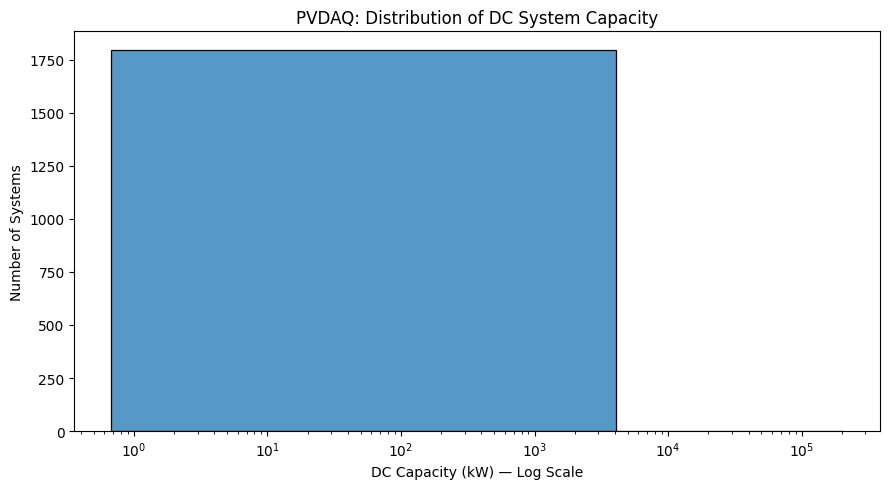

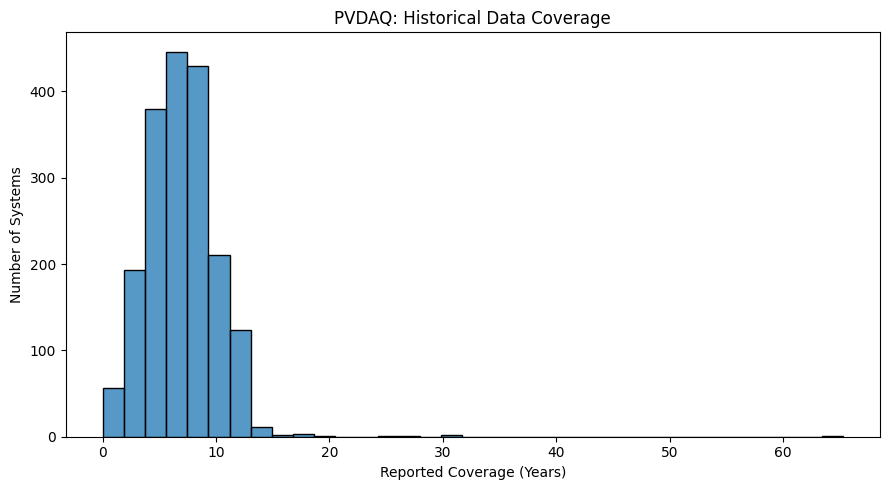

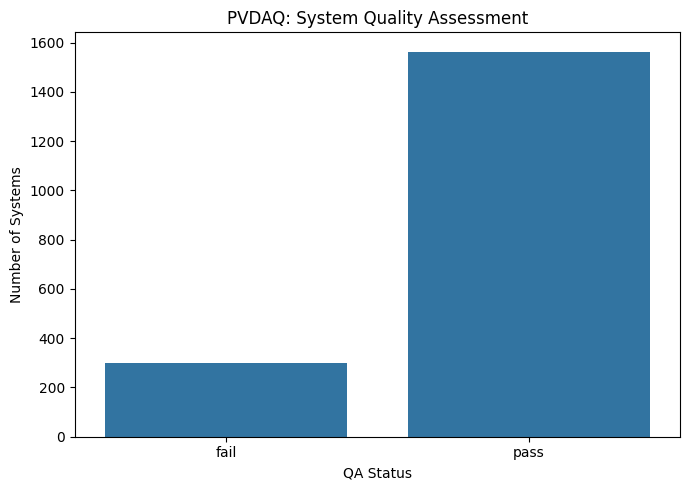

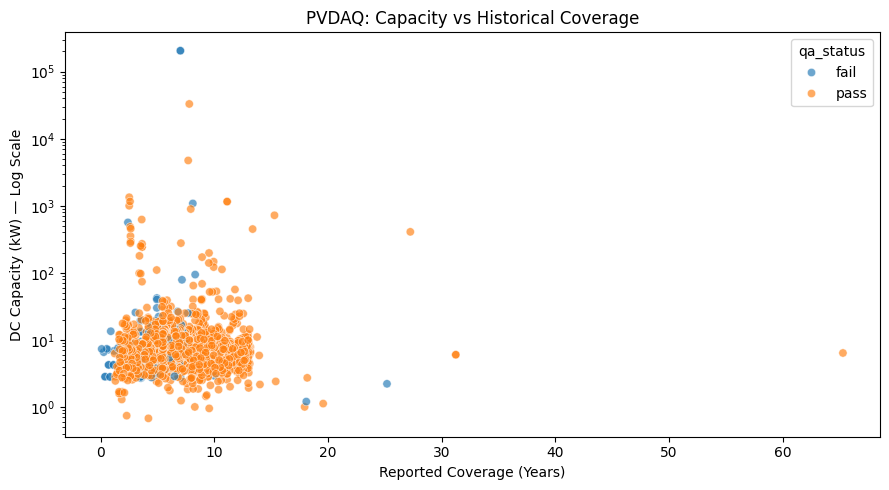

PVDAQ visual EDA completed.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. DC capacity distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_pvdaq_readiness,
    x="dc_capacity_kW",
    bins=50
)
plt.xscale("log")
plt.title("PVDAQ: Distribution of DC System Capacity")
plt.xlabel("DC Capacity (kW) — Log Scale")
plt.ylabel("Number of Systems")
plt.tight_layout()
plt.show()


# 2. Historical data coverage
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_pvdaq_readiness,
    x="years",
    bins=35
)
plt.title("PVDAQ: Historical Data Coverage")
plt.xlabel("Reported Coverage (Years)")
plt.ylabel("Number of Systems")
plt.tight_layout()
plt.show()


# 3. QA status distribution
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df_pvdaq_readiness,
    x="qa_status"
)
plt.title("PVDAQ: System Quality Assessment")
plt.xlabel("QA Status")
plt.ylabel("Number of Systems")
plt.tight_layout()
plt.show()


# 4. Capacity versus historical coverage
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_pvdaq_readiness,
    x="years",
    y="dc_capacity_kW",
    hue="qa_status",
    alpha=0.65
)
plt.yscale("log")
plt.title("PVDAQ: Capacity vs Historical Coverage")
plt.xlabel("Reported Coverage (Years)")
plt.ylabel("DC Capacity (kW) — Log Scale")
plt.tight_layout()
plt.show()

print("PVDAQ visual EDA completed.")

In [ ]:
import os
import zipfile
import pandas as pd

# ============================================================
# 1. CREATE EXPORT DIRECTORIES
# ============================================================

base_dir = "/content/PVDAQ_export"

processed_dir = os.path.join(base_dir, "processed")
metadata_dir = os.path.join(base_dir, "metadata")

os.makedirs(processed_dir, exist_ok=True)
os.makedirs(metadata_dir, exist_ok=True)


# ============================================================
# 2. CREATE PROCESSED CATALOGUE COPY
# ============================================================

df_pvdaq_export = df_pvdaq_readiness.copy()

# Preserve original row position for traceability
df_pvdaq_export.insert(
    0,
    "Source_Row_Index",
    df_pvdaq_export.index
)

# Exclude completely empty columns from analytical export
empty_export_columns = [
    col for col in df_pvdaq_export.columns
    if df_pvdaq_export[col].isna().all()
]

df_pvdaq_export.drop(
    columns=empty_export_columns,
    inplace=True
)

processed_path = os.path.join(
    processed_dir,
    "pvdaq_system_catalogue_processed.csv"
)

df_pvdaq_export.to_csv(processed_path, index=False)


# ============================================================
# 3. FEATURE ROLE REGISTRY
# ============================================================

feature_roles = [
    ("system_id", "System identifier", "Grouping / traceability"),
    ("system_public_name", "Public system name", "Identification only"),
    ("site_location", "Installation location", "Geographic metadata"),
    ("timezone_or_utc_offset", "Timezone or UTC offset", "Temporal alignment"),
    ("latitude", "Latitude", "Geographic metadata"),
    ("longitude", "Longitude", "Geographic metadata"),
    ("elevation_m", "Elevation in metres", "Geographic metadata"),
    ("dc_capacity_kW", "DC system capacity", "System characteristic / normalization"),
    ("kg_climate", "Climate classification", "Environmental metadata"),
    ("pvcz_composite", "Composite PV climate zone", "Climate classification"),
    ("pvcz_t_rack", "Rack temperature climate zone", "Climate classification"),
    ("pvcz_t_roof", "Roof temperature climate zone", "Climate classification"),
    ("pvcz_humidity", "Humidity climate zone", "Climate classification"),
    ("pvcz_wind", "Wind climate zone", "Climate classification"),
    ("tracking", "Tracking configuration", "System configuration"),
    ("type", "PV installation type", "System configuration"),
    ("azimuth", "Panel azimuth", "Panel orientation"),
    ("tilt", "Panel tilt", "Panel orientation"),
    ("first_timestamp", "First available timestamp", "Data coverage metadata"),
    ("last_timestamp", "Last available timestamp", "Data coverage metadata"),
    ("years", "Reported coverage duration", "Data coverage metadata"),
    ("number_records", "Number of records", "Catalogue metadata"),
    ("dataset_size_mb", "Dataset size in MB", "Catalogue metadata"),
    ("available_sensor_channels", "Available sensor channels", "Data-access metadata"),
    ("qa_status", "Quality assessment status", "Quality screening"),
    ("qa_issue", "Quality assessment issue", "Quality screening")
]

df_feature_roles = pd.DataFrame(
    feature_roles,
    columns=[
        "Feature",
        "Description",
        "Role"
    ]
)

df_feature_roles["Modelling_Notes"] = (
    "Catalogue metadata only; not an actual PV measurement feature."
)

df_feature_roles.loc[
    df_feature_roles["Feature"] == "system_id",
    "Modelling_Notes"
] = "Use for system grouping and traceability; never as a numerical predictor."

df_feature_roles.loc[
    df_feature_roles["Feature"] == "azimuth",
    "Modelling_Notes"
] = "Value -1 is a probable unknown sentinel; verify before transformation."

df_feature_roles.loc[
    df_feature_roles["Feature"] == "dc_capacity_kW",
    "Modelling_Notes"
] = "Inspect extreme values; do not remove systems solely by magnitude."

df_feature_roles.to_csv(
    os.path.join(metadata_dir, "pvdaq_feature_roles.csv"),
    index=False
)


# ============================================================
# 4. DATA QUALITY REPORT
# ============================================================

quality_rows = []

for col in df_pvdaq.columns:

    quality_rows.append({
        "Feature": col,
        "Data_Type": str(df_pvdaq[col].dtype),
        "Missing_Count": int(df_pvdaq[col].isna().sum()),
        "Missing_Percentage": round(
            df_pvdaq[col].isna().mean() * 100, 4
        ),
        "Unique_Values": int(df_pvdaq[col].nunique(dropna=True))
    })

df_quality_report = pd.DataFrame(quality_rows)

df_quality_report.to_csv(
    os.path.join(metadata_dir, "pvdaq_data_quality_report.csv"),
    index=False
)


# ============================================================
# 5. SYSTEM SELECTION READINESS REPORT
# ============================================================

readiness_columns = [
    "Valid_Timestamps",
    "Adequate_Coverage",
    "Known_Capacity",
    "Unique_System_ID",
    "QA_Pass",
    "Preliminary_Candidate"
]

readiness_summary = pd.DataFrame({
    "Readiness_Criterion": readiness_columns,
    "Eligible_Systems": [
        int(df_pvdaq_readiness[col].sum())
        for col in readiness_columns
    ],
    "Total_Systems": len(df_pvdaq_readiness)
})

readiness_summary["Percentage"] = (
    readiness_summary["Eligible_Systems"]
    / readiness_summary["Total_Systems"] * 100
).round(2)

readiness_summary.to_csv(
    os.path.join(metadata_dir, "pvdaq_selection_readiness.csv"),
    index=False
)


# ============================================================
# 6. EDA DECISIONS AND VISUAL FINDINGS
# ============================================================

eda_notes = """
PVDAQ SYSTEM CATALOGUE — EDA SUMMARY

DATASET
-------
Original file: systems_20250729.csv
Original dimensions: 1862 rows x 31 columns
Dataset type: PV system catalogue
Not an actual PV measurement time series.

STAGE 1 — MISSING VALUES
-----------------------
Missing catalogue metadata was preserved.
No blanket imputation was performed.
Five completely empty export columns were excluded
from the processed analytical copy.
Original source file remains unchanged.

STAGE 2 — DATA INTEGRITY
-----------------------
Exact duplicate rows: 0
Unique system IDs: 1860
Duplicated system IDs: 2
Invalid timestamp pairs: 2
Future timestamp anomaly: 1
No automatic duplicate removal was performed.

STAGE 3 — DATA QUALITY
----------------------
Negative elevation values were retained.
Azimuth -1 was identified as a probable unknown sentinel.
Extreme capacity and channel counts were flagged for review.
QA status and QA issue were retained separately.
No outlier deletion was performed.

STAGE 4 — FEATURE AND TARGET SUITABILITY
---------------------------------------
System identifiers are for grouping and traceability.
Geographic, climate and configuration fields are metadata.
Capacity is a system characteristic.
Coverage and QA fields are screening metadata.

No actual PV power or energy target was found.
No measurement-level timestamp series was present.
The catalogue cannot independently train a PV generation model.

STAGE 5 — PREPROCESSING READINESS
---------------------------------
Preliminary candidate systems: 1558.
Candidate screening used:
- Valid timestamp boundaries
- At least one year reported coverage
- Known positive DC capacity
- Unique system ID
- QA pass

These are preliminary catalogue-selection criteria,
not confirmation of accessible measurement data.

VISUAL EDA
----------
1. DC capacity is strongly right-skewed.
2. Most systems have relatively low DC capacity.
3. Most reported coverage durations are approximately
   4 to 10 years.
4. QA-passed systems substantially outnumber failed systems.
5. Most systems cluster at low capacity and moderate
   historical coverage.
6. No obvious strong linear relationship between capacity
   and coverage duration was observed.

FINAL LIMITATIONS
-----------------
Actual PV power/energy measurements are not included.
Actual measurement timestamps are not included.
Sampling intervals are unknown.
Sensor-channel definitions require verification.
Timezone normalization requires actual measurement data.
Cross-dataset temporal alignment remains pending.

FINAL DECISION
--------------
The catalogue is suitable for PV system discovery and
preliminary system selection.

It is not a modelling-ready PV generation dataset.

Original data was preserved.
"""

with open(
    os.path.join(metadata_dir, "pvdaq_eda_decisions.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(eda_notes)


# ============================================================
# 7. CREATE ZIP PACKAGE
# ============================================================

zip_path = "/content/PVDAQ_processed_and_metadata.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for folder, _, files in os.walk(base_dir):

        for filename in files:

            filepath = os.path.join(folder, filename)

            arcname = os.path.relpath(
                filepath,
                base_dir
            )

            zipf.write(filepath, arcname)


# ============================================================
# 8. FINAL EXPORT AUDIT
# ============================================================

print("=" * 65)
print("PVDAQ EXPORT COMPLETED")
print("=" * 65)

print("\nPROCESSED FILES")
print("- pvdaq_system_catalogue_processed.csv")

print("\nMETADATA FILES")
print("- pvdaq_feature_roles.csv")
print("- pvdaq_data_quality_report.csv")
print("- pvdaq_selection_readiness.csv")
print("- pvdaq_eda_decisions.txt")

print("\nOriginal catalogue shape:", df_pvdaq.shape)
print("Processed catalogue shape:", df_pvdaq_export.shape)
print("Preliminary candidate systems:",
      int(df_pvdaq_readiness["Preliminary_Candidate"].sum()))

print("\nOriginal dataframe preserved:",
      df_pvdaq.equals(pd.read_csv(pvdaq_path)))

print("\nZIP FILE:", zip_path)
print("ZIP SIZE (MB):",
      round(os.path.getsize(zip_path) / (1024 ** 2), 3))

print("\nExport audit complete.")

PVDAQ EXPORT COMPLETED

PROCESSED FILES
- pvdaq_system_catalogue_processed.csv

METADATA FILES
- pvdaq_feature_roles.csv
- pvdaq_data_quality_report.csv
- pvdaq_selection_readiness.csv
- pvdaq_eda_decisions.txt

Original catalogue shape: (1862, 31)
Processed catalogue shape: (1862, 36)
Preliminary candidate systems: 1558

Original dataframe preserved: True

ZIP FILE: /content/PVDAQ_processed_and_metadata.zip
ZIP SIZE (MB): 0.134

Export audit complete.
